In [1]:
import pandas as pd
pd.set_option('display.float_format', lambda x: f'{x:.2f}')

from glob import glob
import os

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

In [2]:
corpora = pd.read_parquet("../corpora/GeneratedCorpus/corpora_v3.parquet")
corpora = corpora.reset_index(names='text_id')

In [4]:
causal_sliding = pd.DataFrame()

# Carregando zero-shot causal_sliding
zs_cs_folder = "../results_grammar_and_lexical/results"
files = glob(zs_cs_folder + "/*")

for file in files:
    temp = pd.read_csv(file)
    temp["knowledge"] = "Zero-Shot"
    causal_sliding = pd.concat([causal_sliding, temp])
    
    
models = os.listdir("../outputs_ag_news_pt_lora/")
for model in models:
    # Carregando fine-tuning causal_sliding
    temp = pd.read_csv(f"../outputs_ag_news_pt_lora/{model}/ag_news_pt_eval_causal_sliding.csv")
    temp["model"] = model
    temp["knowledge"] = "Fine-Tuning"
    causal_sliding = pd.concat([causal_sliding, temp])
        
causal_sliding = pd.merge(causal_sliding, corpora)

model_order = [
    "Manaca",
    "Tucano-2b4",
    "Cabrita",
    "Sabia 7B",
    "Llama3.1",
    "Qwen3.5-9B",
    "Gemma4-12B",
]

causal_sliding["model"] = pd.Categorical(
    causal_sliding["model"],
    categories=model_order,
    ordered=True
)

causal_sliding = causal_sliding[causal_sliding["language"].isin(["INGLÊS", "ESPANHOL", "PB NATIVO"])]
causal_sliding = causal_sliding[~causal_sliding["scenario"].isin(["GRAMMAR SWAP", "GRAMMAR SWAP v2"])]

In [4]:
causal_sliding[
    (causal_sliding["knowledge"] == "Fine-Tuning") 
].model.value_counts()

model
Manaca        738
Tucano-2b4    738
Cabrita       738
Sabia 7B      738
Llama3.1      738
Qwen3.5-9B    738
Gemma4-12B    738
Name: count, dtype: int64

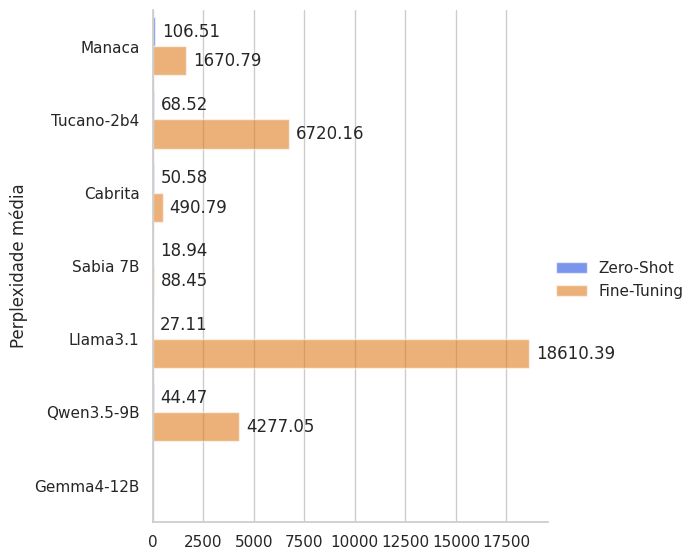

In [5]:
causal_sliding = causal_sliding[causal_sliding["model"] != "Gemma4-12B"]

g = sns.catplot(
    data=causal_sliding,
    kind="bar",
    y="model", x="ppl", orient="h", 
    hue="knowledge",
    estimator="mean", errorbar=None, 
    palette="bright", alpha=.6, height=6, 
)

g.set_axis_labels("", "Perplexidade média")
g.legend.set_title("")

for ax in g.axes.flat:
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", padding=5)

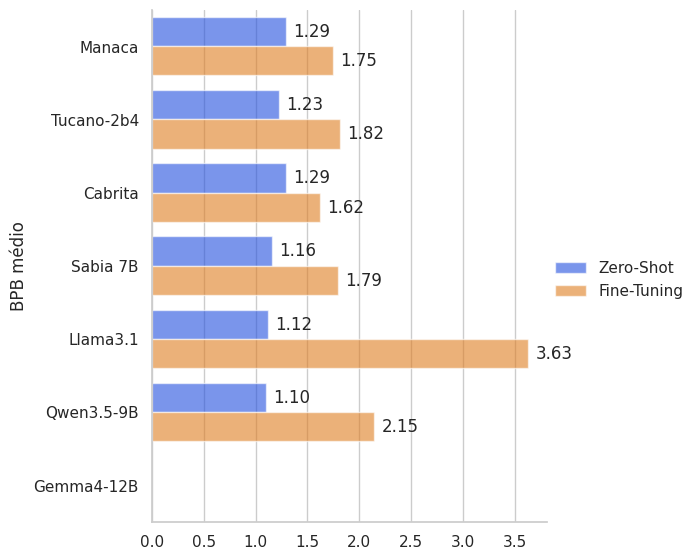

In [6]:
g = sns.catplot(
    data=causal_sliding,
    kind="bar",
    y="model", x="bpb", orient="h", 
    hue="knowledge",
    estimator="mean", errorbar=None, 
    palette="bright", alpha=.6, height=6, 
)

g.set_axis_labels("", "BPB médio")

g.legend.set_title("")

for ax in g.axes.flat:
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", padding=5)

In [7]:
causal_sliding.columns

Index(['text_id', 'num_words', 'num_bytes', 'num_tokens', 'tokens_per_word',
       'average_nll', 'total_nll', 'ppl', 'bpb', 'model', 'knowledge',
       'scenario', 'language', 'task', 'task_type', 'text'],
      dtype='str')

In [8]:
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(causal_sliding.groupby(["model", "knowledge", "scenario"])["ppl"].mean())


model       knowledge    scenario       
Manaca      Fine-Tuning  GRAMMAR SWAP v3     511.32
                         LEXICAL SWAP         98.65
                         PB CORRUPTED       1340.08
                         PB NATIVO           207.55
                         PB PERMUTED       12172.91
                         TRANSLATION          48.30
            Zero-Shot    GRAMMAR SWAP v3      42.51
                         LEXICAL SWAP         39.30
                         PB CORRUPTED        131.31
                         PB NATIVO            32.93
                         PB PERMUTED         585.13
                         TRANSLATION          22.79
Tucano-2b4  Fine-Tuning  GRAMMAR SWAP v3    1174.55
                         LEXICAL SWAP         60.31
                         PB CORRUPTED       5304.94
                         PB NATIVO           249.77
                         PB PERMUTED       52388.70
                         TRANSLATION          34.14
            Zero-Shot  

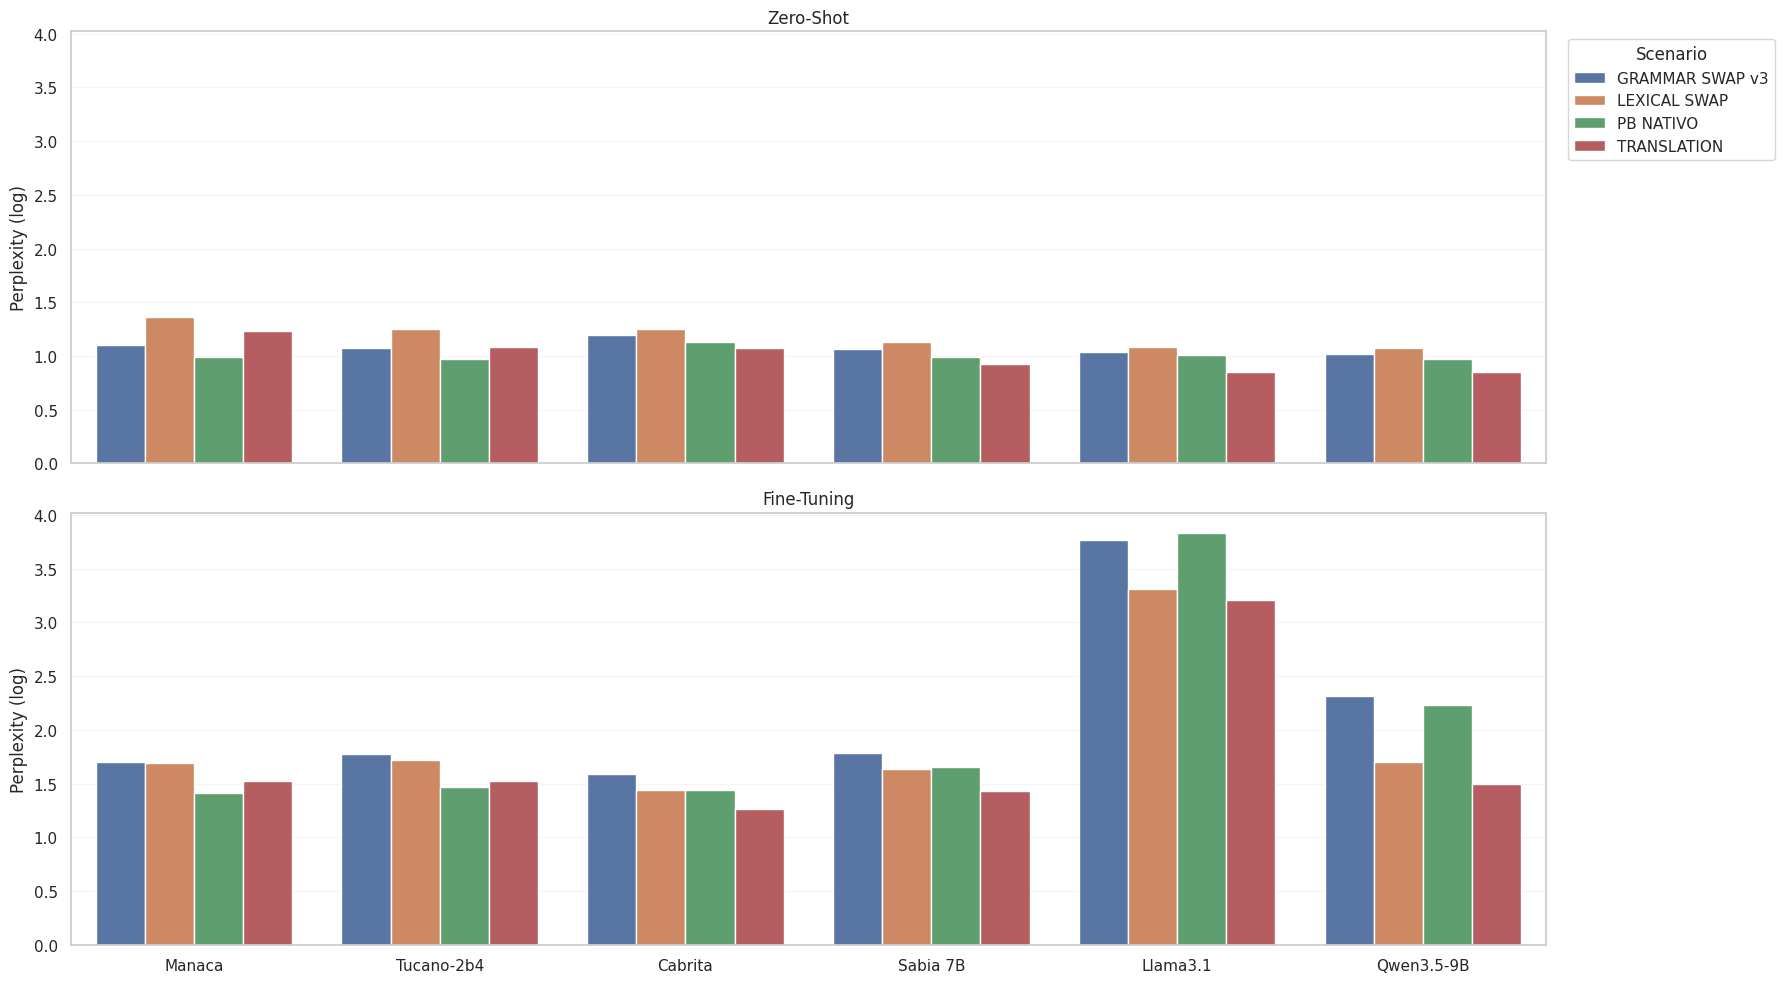

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

metrica = "bpb"

df = (
    causal_sliding
    .groupby(["model", "knowledge", "scenario"], as_index=False)[metrica]
    .mean()
)

df = df[~df["model"].isin(["Gemma4-12B"])]
df = df[~df["scenario"].isin(["PB CORRUPTED", "PB PERMUTED"])]

model_order = df["model"].unique()
scenario_order = df["scenario"].unique()

fig, axes = plt.subplots(
    2, 1,
    figsize=(18, 10),
    sharex=True,
    sharey=True
)

for ax, knowledge in zip(axes, ["Zero-Shot", "Fine-Tuning"]):
    sns.barplot(
        data=df[df["knowledge"] == knowledge],
        x="model",
        y=metrica,
        hue="scenario",
        order=model_order,
        hue_order=scenario_order,
        ax=ax
    )

    #ax.set_yscale("log")
    ax.set_title(knowledge)
    ax.set_ylabel("Perplexity (log)")
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=.2)

axes[0].legend(
    title="Scenario",
    bbox_to_anchor=(1.01, 1),
    loc="upper left"
)
axes[1].legend_.remove()

plt.tight_layout()
plt.show()

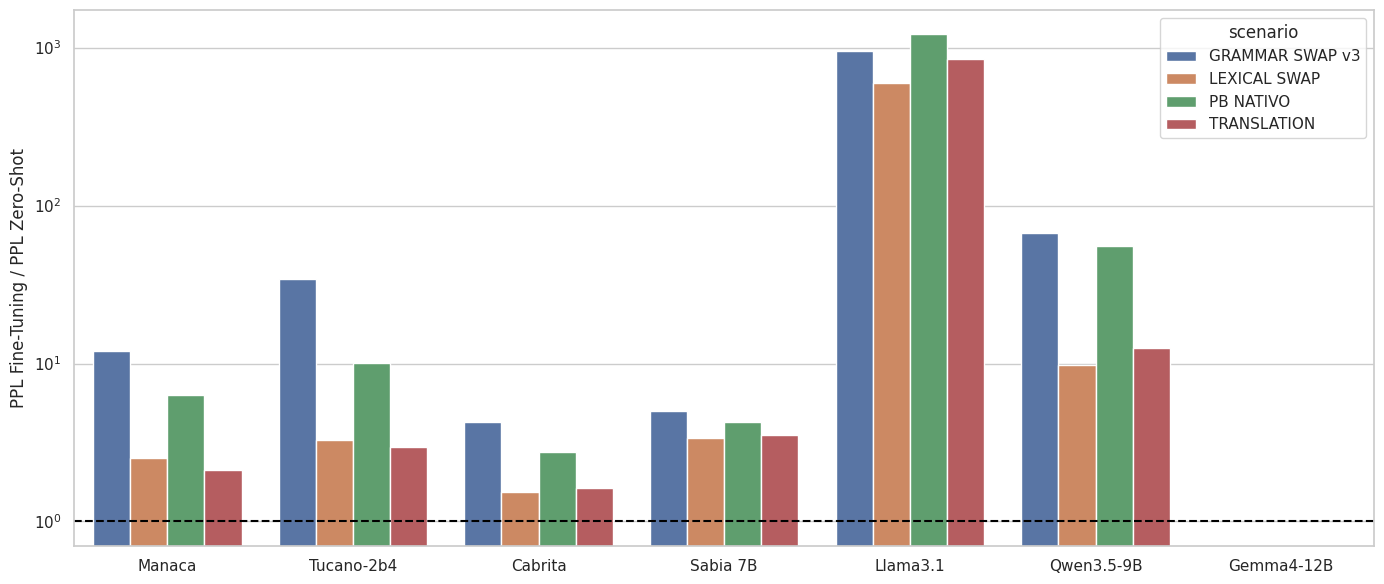

In [55]:
ratio = (
    df.pivot(
        index=["model", "scenario"],
        columns="knowledge",
        values=metrica
    )
    .reset_index()
)

ratio["ratio"] = ratio["Fine-Tuning"] / ratio["Zero-Shot"]

plt.figure(figsize=(14, 6))

sns.barplot(
    data=ratio,
    x="model",
    y="ratio",
    hue="scenario"
)

plt.axhline(1, color="black", linestyle="--")
plt.yscale("log")
plt.ylabel("PPL Fine-Tuning / PPL Zero-Shot")
plt.xlabel("")
plt.tight_layout()
plt.show()

# AG News

In [56]:
import json

In [57]:
models = os.listdir("../outputs_ag_news_pt_lora/")

hatebr = dict()
for model in models:
    # Carregando fine-tuning causal_sliding
    hatebr[model] = dict()
    
    with open(f"../outputs_ag_news_pt_lora/{model}/ag_news_pt_zero_shot_metrics.json") as f:
        hatebr[model]["zero-shot"] = json.load(f)
    
    with open(f"../outputs_ag_news_pt_lora/{model}/ag_news_pt_finetuned_metrics.json") as f:
            hatebr[model]["fine-tuning"] = json.load(f)
    

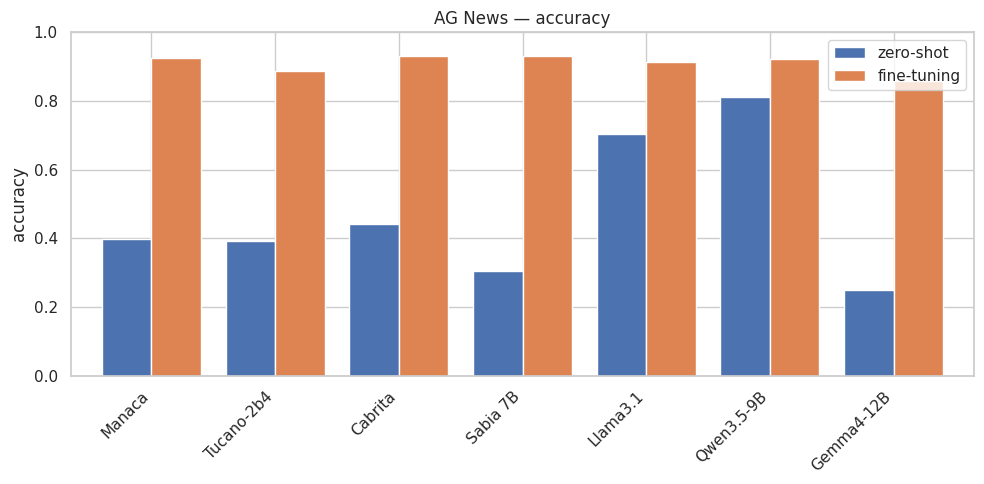

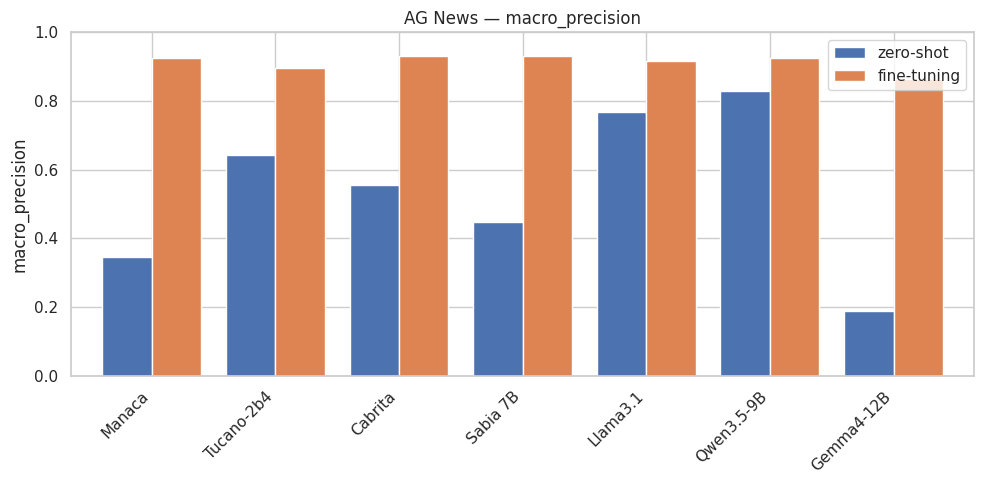

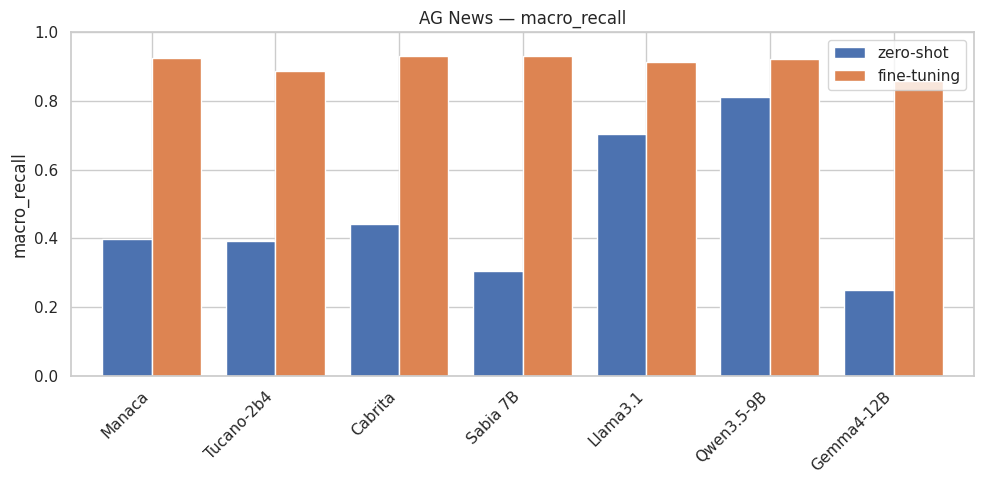

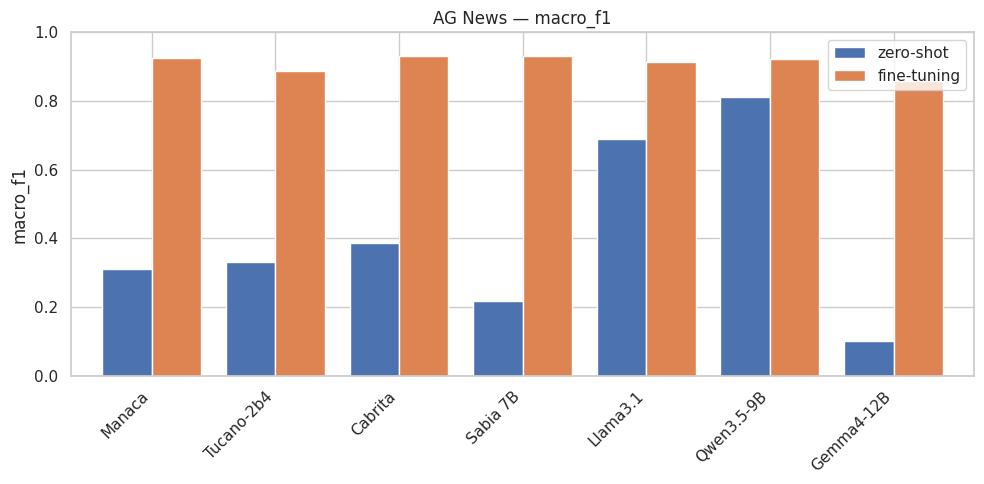

In [59]:
import pandas as pd
import matplotlib.pyplot as plt

metrics = ["accuracy", "macro_precision", "macro_recall", "macro_f1"]

rows = []
for model, results in hatebr.items():
    for setup in ["fine-tuning", "zero-shot"]:
        rows.append({
            "model": model,
            "setup": setup,
            **{m: results[setup][m] for m in metrics}
        })

df = pd.DataFrame(rows)

model_order = [
    "Manaca",
    "Tucano-2b4",
    "Cabrita",
    "Sabia 7B",
    "Llama3.1",
    "Qwen3.5-9B",
    "Gemma4-12B",
]

df["model"] = pd.Categorical(
    df["model"],
    categories=model_order,
    ordered=True
)


for metric in metrics:
    pivot = df.pivot(index="model", columns="setup", values=metric)
    pivot = pivot[["zero-shot", "fine-tuning"]]

    ax = pivot.plot(
        kind="bar",
        figsize=(10, 5),
        ylim=(0, 1),
        width=0.8
    )

    ax.set_title(f"AG News — {metric}")
    ax.set_xlabel("")
    ax.set_ylabel(metric)
    ax.legend(title="")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

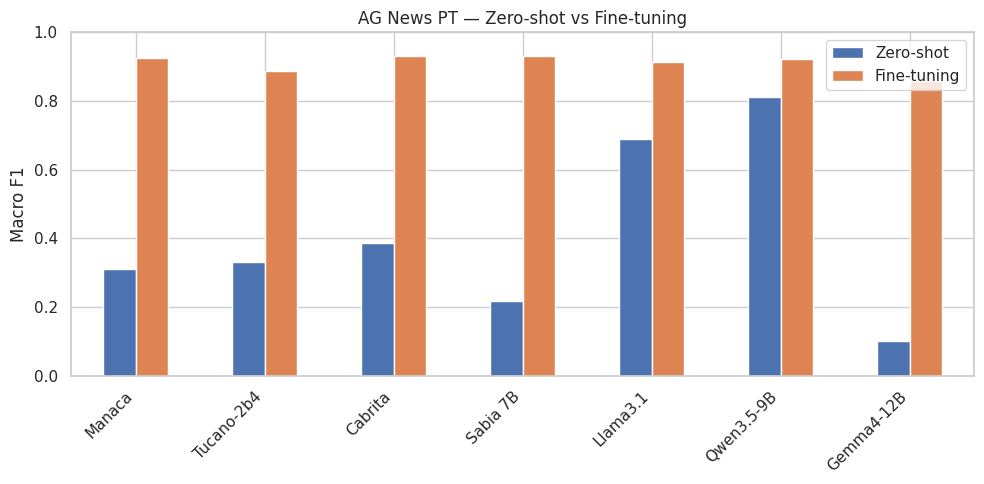

In [63]:
df_f1 = pd.DataFrame({
    model: {
        "Zero-shot": r["zero-shot"]["macro_f1"],
        "Fine-tuning": r["fine-tuning"]["macro_f1"]
    }
    for model, r in hatebr.items()
}).T



model_order = [
    "Manaca",
    "Tucano-2b4",
    "Cabrita",
    "Sabia 7B",
    "Llama3.1",
    "Qwen3.5-9B",
    "Gemma4-12B",
]

# df_f1: modelos estão no índice
df_f1 = df_f1.reindex(model_order)


ax = df_f1.plot.bar(figsize=(10, 5), ylim=(0, 1))

ax.set_title("AG News PT — Zero-shot vs Fine-tuning")
ax.set_ylabel("Macro F1")
ax.set_xlabel("")
ax.legend(title="")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [61]:
import pandas as pd

metrics = ["accuracy", "macro_precision", "macro_recall", "macro_f1"]

rows = []
for model, results in hatebr.items():
    for metric in metrics:
        zero = results["zero-shot"][metric]
        ft = results["fine-tuning"][metric]

        rows.append({
            "Modelo": model,
            "Métrica": metric,
            "Zero-shot": zero,
            "Fine-tuning": ft,
            "Ganho (%)": (ft - zero) / zero * 100 if zero != 0 else float("nan")
        })

df_results = pd.DataFrame(rows)

df_results["Modelo"] = pd.Categorical(
    df_results["Modelo"],
    categories=model_order,
    ordered=True
)

df_results = df_results.sort_values(
    ["Modelo"]
)

display(
    df_results.style
    .format({
        "Zero-shot": "{:.4f}",
        "Fine-tuning": "{:.4f}",
        "Ganho (%)": "{:+.2f}%"
    })
    # .background_gradient(subset=["Ganho (%)"], cmap="RdYlGn")
)

,Modelo,Métrica,Zero-shot,Fine-tuning,Ganho (%)
19,Manaca,macro_f1,0.3122,0.9251,+196.36%
17,Manaca,macro_precision,0.3461,0.9263,+167.65%
16,Manaca,accuracy,0.3967,0.9251,+133.20%
18,Manaca,macro_recall,0.3967,0.9251,+133.20%
11,Tucano-2b4,macro_f1,0.3308,0.8867,+168.05%
10,Tucano-2b4,macro_recall,0.3932,0.8883,+125.94%
8,Tucano-2b4,accuracy,0.3932,0.8883,+125.94%
9,Tucano-2b4,macro_precision,0.6433,0.8953,+39.16%
26,Cabrita,macro_recall,0.4405,0.9300,+111.11%
24,Cabrita,accuracy,0.4405,0.9300,+111.11%


In [62]:
display(
    df_results[df_results["Métrica"] == "accuracy"]
    #.sort_values("Ganho (%)", ascending=False)
    .style.format({
        "Zero-shot": "{:.4f}",
        "Fine-tuning": "{:.4f}",
        "Ganho (%)": "{:+.2f}%"
    })
)

,Modelo,Métrica,Zero-shot,Fine-tuning,Ganho (%)
16,Manaca,accuracy,0.3967,0.9251,+133.20%
8,Tucano-2b4,accuracy,0.3932,0.8883,+125.94%
24,Cabrita,accuracy,0.4405,0.9300,+111.11%
4,Sabia 7B,accuracy,0.3063,0.9314,+204.08%
20,Llama3.1,accuracy,0.7037,0.9138,+29.86%
12,Qwen3.5-9B,accuracy,0.8112,0.9221,+13.67%
0,Gemma4-12B,accuracy,0.2504,0.8589,+243.04%
